# Plot results from test_methods.py

The results are stored in a DataFrame with the following columns:
- method: Source reconstruction method
- region: Region onset of spike source
- half: EEG peak half rising time
- peak: EEG peak time

The following columns shows the correlation achieved by the method over multiple time points. <br>

## 📦 Imports

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `corrs`: Source reconstruction correlations over time.

In [3]:
select_methods = [
    "cset",
    "sloreta",
    "wcset",
]

results = pd.read_csv("test_methods.csv")
results = results[results["method"].isin(select_methods)]
print(results.shape)
results.head(3)

(99000, 6)


,timepoint,correlation,method,region,half,peak
0,0.500,0.000000,cset,ctx-lh-precentral_1,False,False
1,0.504,0.025445,cset,ctx-lh-precentral_1,False,False
2,0.508,0.039083,cset,ctx-lh-precentral_1,False,False


#### ⚙️ **<font color=green>Plot correlation at half rising phase and peak phase</font>**

<Axes: xlabel='peak', ylabel='correlation'>

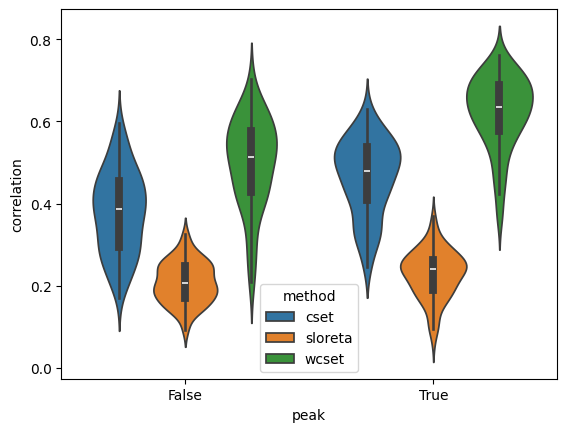

In [4]:
points = results[results["half"] | results["peak"]]
points = points.groupby(["method", "region", "half", "peak"]).mean()

sns.violinplot(data=points, x="peak", y="correlation", hue="method")

#### ⚙️ **<font color=green>Plot correlation over time</font>**

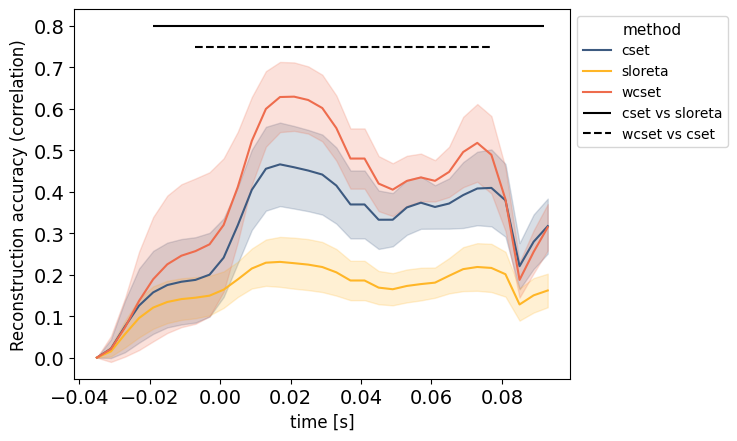

In [30]:
ts = results.drop(["half", "peak"], axis=1)
ts = ts.groupby(["method", "region", "timepoint"]).mean().reset_index()

# subtract sloreta mean
baseline_mean = ts[ts["method"] == "sloreta"].groupby("timepoint")["correlation"].mean().reset_index()
baseline_mean = baseline_mean.rename(columns={"correlation": "baseline_mean_correlation"})

ts_merged = ts.merge(baseline_mean, on="timepoint", how="left")
ts_merged["difference_from_baseline"] = ts_merged["correlation"] - ts_merged["baseline_mean_correlation"]

colors = [
    "#3d5a80",
    "#ffb627",
    "#ee6c4d",
]

ts_merged["timepoint"] = ts_merged["timepoint"] - 0.535

ax = sns.lineplot(data=ts_merged, x="timepoint", y="correlation", hue="method", palette=colors, errorbar=("sd", 1))
ax.set_xlabel("time [s]", fontsize=12)
ax.set_ylabel("Reconstruction accuracy (correlation)", fontsize=12)
ax.tick_params(labelsize=14)
ax.hlines(y=0.8, xmin=-0.019, xmax=0.092, linestyles="-", colors="black", label="cset vs sloreta")
ax.hlines(y=0.75, xmin=-0.007, xmax=0.077, linestyles="--", colors="black", label="wcset vs cset")
plt.legend(title = "method", fontsize='10', title_fontsize='11')
sns.move_legend(
    ax, "upper left",
    bbox_to_anchor=(1,1)
)

In [83]:
ts["timepoint"] = ts["timepoint"] - 0.525

In [54]:
test = ts_merged.groupby(["method", "timepoint"])["correlation"].agg(["mean", "std"]).reset_index()
test[(test["timepoint"]>0) & (test["timepoint"]<0.25) & (test["method"]=="wcset")]

,method,timepoint,mean,std
75,wcset,0.001,0.319889,0.160773
76,wcset,0.005,0.411106,0.133279
77,wcset,0.009,0.522769,0.105748
78,wcset,0.013,0.599886,0.091038
79,wcset,0.017,0.628523,0.084590
80,wcset,0.021,0.629405,0.082549
81,wcset,0.025,0.621376,0.081044
82,wcset,0.029,0.601976,0.080307
83,wcset,0.033,0.553529,0.078592
84,wcset,0.037,0.480122,0.072602


# Plot results from test_sabotage.py

The results are stored in a DataFrame with the following columns:
- subject: Template subject
- method: Source reconstruction method
- region: Region onset of spike source
- correlation: Correlation at peak time

## 📦 Imports

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `sabotage`: Source reconstruction correlations for various degrees of connectome sabotaging

In [60]:
sabotage = pd.read_csv("sabotage.csv")
print(sabotage.shape)
sabotage = sabotage[sabotage["method"].isin(["cset", "sloreta", "geometry", "template"])]
sabotage.head(3)

(15000, 5)


,subject,method,location,correlation,sabotage
0,vepcon_sub-10,geometry,ctx-rh-precentral_14,0.365505,0.0
1,vepcon_sub-10,template,ctx-rh-precentral_14,0.330471,0.0
2,vepcon_sub-10,sloreta,ctx-rh-precentral_14,0.174292,0.0


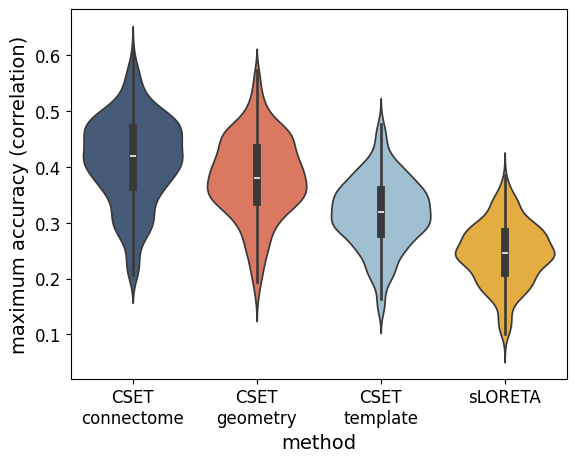

In [61]:
df = sabotage[sabotage["sabotage"]==0]
ax = sns.violinplot(df, x="method", y="correlation", hue="method", order=["cset", "geometry", "template", "sloreta"], palette=["#ee6c4d", "#98c1d9",  "#ffb627", "#3d5a80",])
ax.set_xlabel("method", fontsize=14)
ax.set_ylabel("maximum accuracy (correlation)", fontsize=14)
ax.set_xticks(ticks=[0,1,2,3], labels=["CSET\nconnectome", "CSET\ngeometry", "CSET\ntemplate", "sLORETA"])
ax.tick_params(labelsize=12)

In [62]:
df[df["method"]=="sloreta"]["correlation"].mean()

np.float64(0.24507650518462487)

/tmp/ipykernel_24800/2638416165.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sabotage"] = df["sabotage"]*100


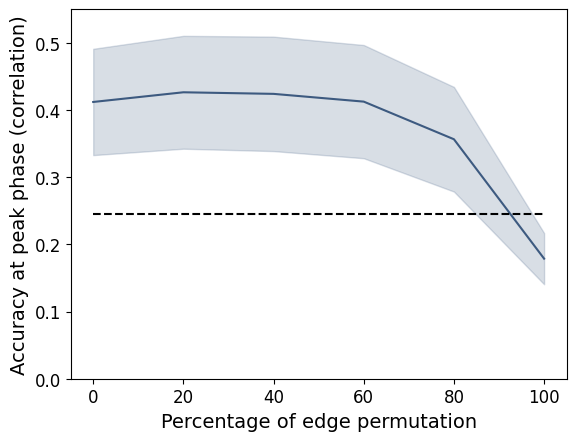

In [58]:
df = sabotage[sabotage["method"]=="cset"]
df["sabotage"] = df["sabotage"]*100
ax = sns.lineplot(df, x="sabotage", y="correlation", color="#3d5a80", errorbar=("sd", 1))
ax.set_ylabel("Accuracy at peak phase (correlation)", fontsize=14)
ax.set_xlabel("Percentage of edge permutation", fontsize=14)
ax.tick_params(labelsize=12)
ax.set(ylim=(0,0.55))
ax.hlines(y=0.245, xmin=0, xmax=100, color="black", linestyles="--")

<Axes: xlabel='sabotage', ylabel='correlation'>

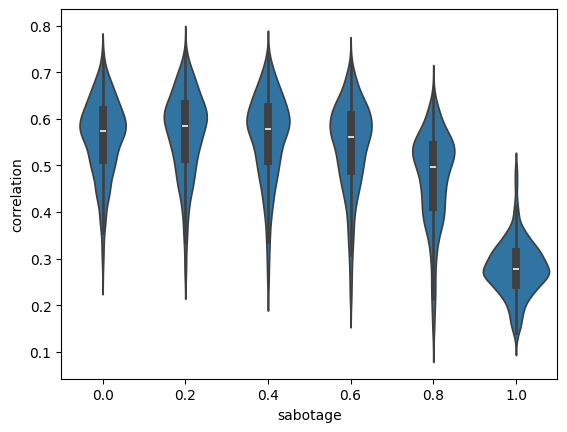

In [9]:
df = sabotage[sabotage["method"]=="wcset"]
sns.violinplot(df, x="sabotage", y="correlation")

In [75]:
import numpy as np
from scipy.stats import t, chi2
from itertools import combinations

def compare_curves(
        df          : pd.DataFrame,
        value_col   : str,
        pairing_col : str,
        group_col   : str,
        alpha       : float = 0.05,
        plot        : bool = False,
        plot_params : dict = None,
) -> np.ndarray:
    """
    Compares multiple curves using the modified Chi-squared test and applies Bonferroni corrections for
    multiple pairwise comparisons and post hoc analysis.

    Parameters
    ----------
    df: pd.DataFrame
        DataFrame containing  data.
    pairing_col: str
        Name of the columns with pairings (x axis)
    value_col: str
        Name of the columns with values (y axis).
    group_col: str
        Name of the columns defining the curves (hue).
    alpha: float [0-1]
        Overall significance level (default 0.05)
    plot: bool
        Whether to plot the results
    plot_params: dict
        Plot parameters.

    Returns
    -------
    dict: Results including overall comparison and post hoc analysis.
    """
    # comparisons
    groups          = df[group_col].unique()
    combis          = list(combinations(groups, 2))
    num_comparisons = len(combis)

    # statistics
    statistics = df.groupby([group_col, pairing_col])[value_col].agg(["mean", "sem", "count"])
    num_points = statistics.index.get_level_values(pairing_col).nunique()
    print(statistics)
    
    # 1. Bonferroni correction for multiple curves
    alpha_corr_overall = alpha / num_comparisons if num_comparisons > 0 else alpha

    # 2. Bonferroni correction for post hoc analysis (multiple time points)
    alpha_corr_point = alpha / num_points

    overall_results = []
    post_hoc_results = {}

    print(f"Total Curves: {len(groups)}")
    print(f"Total Pairwise Comparisons (K): {num_comparisons}")
    print(f"Corrected Overall significance level: {alpha_corr_overall:.4f}")
    print(f"Total Matched Points (M): {num_points}")
    print(f"Corrected Post Hoc significance level: {alpha_corr_point:.4f}")

    # -----------------------------
    # Perform Pairwise Comparisons
    # -----------------------------
    for group_a, group_b in combis:
        # Get data for curve A and curve B, sorted by pairings
        data_a = statistics.loc[group_a].sort_index()
        data_b = statistics.loc[group_b].sort_index()

        # check if pairings match after sorting
        if not all(data_a.index.values == data_b.index.values):
            raise ValueError(f"Pairings do not match or are not unique for curves {group_a} and {group_b}.")
        
        # extract parameters
        means_a, se_a, n_a = data_a["mean"].values, data_a["sem"].values, data_a["count"].values
        means_b, se_b, n_b = data_b["mean"].values, data_b["sem"].values, data_b["count"].values

        # run the core test
        try:
            results = modified_chi_squared_test(means_a, se_a, n_a, means_b, se_b, n_b)
        except ValueError as e:
            print(f"Skipping comparison {group_a} vs {group_b} due to error: {e}")
            continue

        # 1. Overall Results
        overall_results.append({
            "Comparison": f"{group_a} vs {group_b}",
            "Chi_Sum_Sq": results["chi_sum_sq"],
            "df": results["df"],
            "P_value": results["p_value"],
            "P_value_Corrected_Overall": results["p_value"] * num_comparisons,
            "Significant_Overall": results["p_value"] < alpha_corr_overall
        })

        # 2. Post Hoc Results (Individual Point Comparison)
        # Store individual results for time points (x-axis)
        post_hoc_df = pd.DataFrame({
            pairing_col: data_a.index.values,
            "P_value_Point": results["point_p_values"]
        })

        # Apply Bonferroni correction for M points
        post_hoc_df["P_value_Corrected_Point"] = post_hoc_df["P_value_Point"] * num_points
        # NOTE: The paper uses: p_i < alpha_corr_point for significance (using the t-test p-value)
        post_hoc_df["Significant_Point"] = post_hoc_df["P_value_Point"] < alpha_corr_point

        # Clean up corrected p-values (max 1.0)
        post_hoc_df["P_value_Corrected_Point"] = post_hoc_df["P_value_Corrected_Point"].clip(upper=1.0)

        post_hoc_results[f"{group_a} vs {group_b}"] = post_hoc_df

    return {
        "overall_comparison_results": pd.DataFrame(overall_results),
        "post_hoc_point_results": post_hoc_results,
        "alpha_corrected_overall": alpha_corr_overall,
        "alpha_corrected_point": alpha_corr_point,
    }

def modified_chi_squared_test(
        means_a : np.ndarray,
        se_a    : np.ndarray,
        n_a     : np.ndarray | int,
        means_b : np.ndarray,
        se_b    : np.ndarray,
        n_b     : np.ndarray | int,
) -> np.ndarray:
    """
    Performs the Modified Chi-squared Test for comparing two arbitrary curves (scenario 2: N > 1
    measurements, giving Mean and SE), based on the method by Hristova and Wimley (PMC10617697)

    This method uses the t-distribution to correct for small sample sizes at each point
    before summing the individual differences via the Chi-squared formalism.

    Parameters:
    ----------
    means_a: array-like
        Array of mean Y-values for Curve A.
    se_a: array-like
        Array of Standard Errors (SE) for Curve A.
    n_a: array-like or int
        Array of sample sizes (N) for each point in Curve A, or a single integer if N is constant.
    means_b: array-like
        Array of mean Y-values for Curve B.
    se_b: array-like
        Array of Standard Errors (SE) for Curve B.
    n_b: array-like
        Array of sample sizes (N) for each point in Curve B, or a single integer if N is constant.

    Returns:
    -------
    dict: A dictionary containing the overall Chi-squared sum (chi_sum_sq), the degrees of freedom (df), and 
    the overall p-value.
    """
    # Convert inputs to numpy arrays for vectorized operations
    O_a  = np.asarray(means_a)
    SE_a = np.asarray(se_a)
    N_a  = np.atleast_1d(np.asarray(n_a))
    O_b  = np.asarray(means_b)
    SE_b = np.asarray(se_b)
    N_b  = np.atleast_1d(np.asarray(n_b))

    # Ensure all arrays have the same length (M = number of points)
    if not (O_a.size == SE_a.size == O_b.size == SE_b.size):
        raise ValueError("Input arrays for means and SE must have the same length.")
    
    # M is the number of matched pairs of points
    M = O_a.size

    # 1. Calculate the Standard Error of the Difference (SE_i^diff) - Eq 5
    # SE_i^diff = sqrt((SE_i^a)^2 + (SE_i^b)^2)
    SE_diff = np.sqrt(SE_a**2 + SE_b**2)

    # Handle zero SE_diff to prevent division by zero (must be based on prior knowledge)
    if np.any(SE_diff == 0):
        # NOTE: The paper states "SD/SE values cannot be zero for both curves to be compared"
        print("WARNING: One or both curves have zero standard error for at least one point."
              "Consider substituting a minimal non-zero SE value based on experimental uncertainty")

    # 2. Calculate the t-statistics (t_i) - Eq 7
    # t_i = (O_i^a - O_i^b) / SE_i^diff
    t_stat = (O_a - O_b) / SE_diff

    # 3. Calculate the Degrees of Freedom for t-distribution (dF_i^t)
    # dF_i^t = 2 * N_smaller - 2 (as recommended for different N)
    N_min = np.minimum(N_a.reshape(-1, 1), N_b.reshape(-1, 1)).flatten()
    df_t  = 2 * N_min - 2

    # Points where df_t is <= 0 are invalid for t-test (requires N >= 2 for the min N)
    invalid_df_mask = df_t <= 0
    if np.any(invalid_df_mask):
        raise ValueError(f"Invalid degrees of freedom (df_t <= 0) detected at one or more points."
                         f"This occurs if min(N_a, N_b) is less than 2. Smallest N must be >= 2.")
    
    # 4. Calculate the two-tailed p-value (p_i) from the t-distribution - Eq 8
    # p_i = T-Distribution Two-Tailed Probability(|t_i|, dF_i^t)
    # The sf (survival function) is 1 - cdf, and we use *2 for two tailed,
    # but the scipy.stats.t.sf(t, df) is P(X > t).
    # For two-tailed p-value: 2 * sf(|t_i|, df_t)
    p_i = 2 * t.sf(np.abs(t_stat), df_t)

    # 5. Calculate the Corrected Chi-squared (chi_corr, i^2) - Eq 9
    # chi_corr, i^2 = Inverse Chi-squared(1 - p_i, dF=1)
    # NOTE: 1 - p_i is the cumulative probability (CDF) corresponding to the p-value.
    # The degrees of freedom for the inverse chi2 is always 1 for this step.
    chi_corr_sq = chi2.isf(p_i, df=1)

    # 6. Calculate the Overall Chi_squared Sum (chi_sum^2) - Eq 10
    chi_sum_sq = np.sum(chi_corr_sq)

    # 7. Calculate the Overall P-value (P_overall)
    # P_overall = Chi_squared Survival Function(chi_sum^2, dF_overall = M)
    # The overall degrees of freedom is M, the number of matched pairs.
    df_overall = M
    P_overall = chi2.sf(chi_sum_sq, df_overall)

    return {
        "chi_sum_sq": chi_sum_sq,
        "df": df_overall,
        "p_value": P_overall,
        "point_p_values": p_i,      # needed for post-hoc analysis
        "x_value": np.unique(df_t)  # placeholder for x_values if needed
    }

In [76]:
test = compare_curves(
    df=ts,
    value_col="correlation",
    pairing_col="timepoint",
    group_col="method",
    alpha=0.05
)

                      mean       sem  count
method timepoint                           
cset   0.500      0.000000  0.000000    100
       0.504      0.021442  0.002250    100
       0.508      0.075422  0.006238    100
       0.512      0.125560  0.008946    100
       0.516      0.157367  0.010007    100
...                    ...       ...    ...
wcset  0.612      0.489224  0.009334    100
       0.616      0.381735  0.007625    100
       0.620      0.187516  0.004274    100
       0.624      0.255067  0.005180    100
       0.628      0.314415  0.005591    100

[99 rows x 3 columns]
Total Curves: 3
Total Pairwise Comparisons (K): 3
Corrected Overall significance level: 0.0167
Total Matched Points (M): 33
Corrected Post Hoc significance level: 0.0015


/tmp/ipykernel_4216/1674844249.py:183: RuntimeWarning: invalid value encountered in divide
  t_stat = (O_a - O_b) / SE_diff
/tmp/ipykernel_4216/1674844249.py:183: RuntimeWarning: invalid value encountered in divide
  t_stat = (O_a - O_b) / SE_diff
/tmp/ipykernel_4216/1674844249.py:183: RuntimeWarning: invalid value encountered in divide
  t_stat = (O_a - O_b) / SE_diff


In [77]:
test

{'overall_comparison_results':          Comparison  Chi_Sum_Sq  df  P_value  P_value_Corrected_Overall  \
 0   cset vs sloreta         NaN  33      NaN                        NaN   
 1     cset vs wcset         NaN  33      NaN                        NaN   
 2  sloreta vs wcset         NaN  33      NaN                        NaN   
 
    Significant_Overall  
 0                False  
 1                False  
 2                False  ,
 'post_hoc_point_results': {'cset vs sloreta':     timepoint  P_value_Point  P_value_Corrected_Point  Significant_Point
  0       0.500            NaN                      NaN              False
  1       0.504   1.215081e-02             4.009767e-01              False
  2       0.508   8.297327e-03             2.738118e-01              False
  3       0.512   3.305007e-03             1.090652e-01              False
  4       0.516   1.305335e-03             4.307605e-02               True
  5       0.520   4.360813e-04             1.439068e-02         